In [1]:
from pathlib import Path
import json
import platform
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from scipy.stats import qmc, spearmanr

# All outputs are written relative to the notebook's working directory.
PROJECT_DIR = Path.cwd()
FIGURE_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 20261110
N_LHS = 200

STATE_NAMES = ["I", "S", "R", "M", "T", "F", "C"]
TIME_UNIT = "days"

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Project directory:", PROJECT_DIR.resolve())

Python: 3.14.2
Platform: Linux-6.8.0-1070-azure-x86_64-with-glibc2.39
NumPy: 2.5.4
Pandas: 3.1.1
Project directory: /workspaces/crohns-fibrostenosis-ode-model


In [2]:
# Baseline parameters used in the manuscript.
# Units are day^-1 unless a parameter is a dimensionless saturation constant.
PARAMETERS = {
    "beta_R": 0.03,
    "beta_M": 0.03,
    "delta_I": 0.50,
    "p_S": 0.40,
    "delta_S": 1.00,
    "alpha_R": 0.60,
    "K_S": 0.50,
    "delta_R": 0.70,
    "alpha_M": 0.50,
    "K_I": 0.50,
    "delta_M": 0.35,
    "alpha_T": 0.45,
    "K_M": 0.50,
    "delta_T": 0.25,
    "alpha_FR": 0.35,
    "K_FR": 0.50,
    "alpha_FT": 0.45,
    "K_FT": 0.50,
    "delta_F": 0.12,
    "p_C": 0.25,
    "delta_C": 0.025,
}

PARAMETER_NAMES = list(PARAMETERS.keys())

# Exploratory ranges used for the 21-parameter LHS analysis.
# These are assumptions for uncertainty exploration, not fitted distributions.
PARAMETER_BOUNDS = {
    "beta_R": (0.0, 0.2),
    "beta_M": (0.0, 0.2),
    "delta_I": (0.2, 1.0),
    "p_S": (0.15, 0.8),
    "delta_S": (0.3, 2.0),
    "alpha_R": (0.2, 1.2),
    "K_S": (0.1, 5.0),
    "delta_R": (0.2, 1.5),
    "alpha_M": (0.2, 1.0),
    "K_I": (0.1, 2.0),
    "delta_M": (0.1, 0.8),
    "alpha_T": (0.15, 1.0),
    "K_M": (0.1, 2.0),
    "delta_T": (0.05, 0.6),
    "alpha_FR": (0.1, 0.8),
    "K_FR": (0.1, 2.0),
    "alpha_FT": (0.15, 1.0),
    "K_FT": (0.1, 2.0),
    "delta_F": (0.03, 0.3),
    "p_C": (0.05, 0.6),
    "delta_C": (0.005, 0.08),
}

parameter_table = pd.DataFrame({
    "Parameter": PARAMETER_NAMES,
    "Baseline": [PARAMETERS[k] for k in PARAMETER_NAMES],
    "Lower": [PARAMETER_BOUNDS[k][0] for k in PARAMETER_NAMES],
    "Upper": [PARAMETER_BOUNDS[k][1] for k in PARAMETER_NAMES],
})
display(parameter_table)

parameter_table.to_csv(RESULTS_DIR / "model_A_parameters.csv", index=False)

assert set(PARAMETERS) == set(PARAMETER_BOUNDS)
assert all(v > 0 for v in PARAMETERS.values())
assert all(lo <= PARAMETERS[k] <= hi for k, (lo, hi) in PARAMETER_BOUNDS.items())

,Parameter,Baseline,Lower,Upper
0,beta_R,0.030,0.000,0.20
1,beta_M,0.030,0.000,0.20
2,delta_I,0.500,0.200,1.00
3,p_S,0.400,0.150,0.80
4,delta_S,1.000,0.300,2.00
5,alpha_R,0.600,0.200,1.20
6,K_S,0.500,0.100,5.00
7,delta_R,0.700,0.200,1.50
8,alpha_M,0.500,0.200,1.00
9,K_I,0.500,0.100,2.00


In [3]:
def saturation(x, K):
    """H(x; K) = x / (K + x), for nonnegative x and positive K."""
    return x / (K + x)


def model_rhs(t, y, p, input_amplitude=0.0, input_duration=0.0):
    """Seven-state ODE model in the state order [I, S, R, M, T, F, C]."""
    I, S, R, M, T, F, C = y

    # Piecewise-constant external inflammatory input.
    u = input_amplitude if t < input_duration else 0.0

    dI = u + p["beta_R"] * R + p["beta_M"] * M - p["delta_I"] * I
    dS = p["p_S"] * I - p["delta_S"] * S
    dR = p["alpha_R"] * saturation(S, p["K_S"]) - p["delta_R"] * R
    dM = p["alpha_M"] * saturation(I, p["K_I"]) - p["delta_M"] * M
    dT = p["alpha_T"] * saturation(M, p["K_M"]) - p["delta_T"] * T
    dF = (
        p["alpha_FR"] * saturation(R, p["K_FR"])
        + p["alpha_FT"] * saturation(T, p["K_FT"])
        - p["delta_F"] * F
    )
    dC = p["p_C"] * F - p["delta_C"] * C

    return np.array([dI, dS, dR, dM, dT, dF, dC], dtype=float)


# Check the right-hand side dimension and the zero-state equilibrium without input.
_rhs_zero = model_rhs(0.0, np.zeros(7), PARAMETERS)
assert _rhs_zero.shape == (7,)
assert np.allclose(_rhs_zero, 0.0)
print("ODE system defined: 7 states, 21 parameters.")

ODE system defined: 7 states, 21 parameters.


In [7]:

def calculate_ecm_metrics(time, states):
    """
    Calculate ECM outcomes:
    - Peak ECM
    - Final ECM
    - ECM area under the curve (AUC)
    - Time to peak
    - Whether the peak occurs at the simulation endpoint
    """

    time = np.asarray(time, dtype=float)
    states = np.asarray(states, dtype=float)

    # ECM is the seventh state variable (index 6).
    ecm = states[6, :]

    if len(time) != len(ecm):
        raise ValueError("Time and ECM arrays must have the same length.")

    if len(time) < 2:
        raise ValueError("At least two time points are required.")

    if not np.all(np.isfinite(time)) or not np.all(np.isfinite(ecm)):
        raise ValueError("Time and ECM arrays contain non-finite values.")

    if np.any(np.diff(time) <= 0):
        raise ValueError("Time values must be strictly increasing.")

    peak_index = int(np.argmax(ecm))

    # Compatible with NumPy 2.x and older NumPy versions.
    if hasattr(np, "trapezoid"):
        auc = np.trapezoid(ecm, time)
    else:
        auc = np.trapz(ecm, time)

    return {
        "Peak_ECM": float(np.max(ecm)),
        "Final_ECM": float(ecm[-1]),
        "ECM_AUC": float(auc),
        "Time_to_peak_days": float(time[peak_index]),
        "Peak_at_final_time": bool(peak_index == len(time) - 1),
    }


In [9]:

# Recalculate baseline metrics before plotting
baseline_metrics = calculate_ecm_metrics(
    baseline_time,
    baseline_states
)

print("Baseline metrics:")
for key, value in baseline_metrics.items():
    print(f"{key}: {value}")

Baseline metrics:
Peak_ECM: 4.881117232924121
Final_ECM: 3.0899555369174707
ECM_AUC: 198.80294971755185
Time_to_peak_days: 31.900000000000002
Peak_at_final_time: False


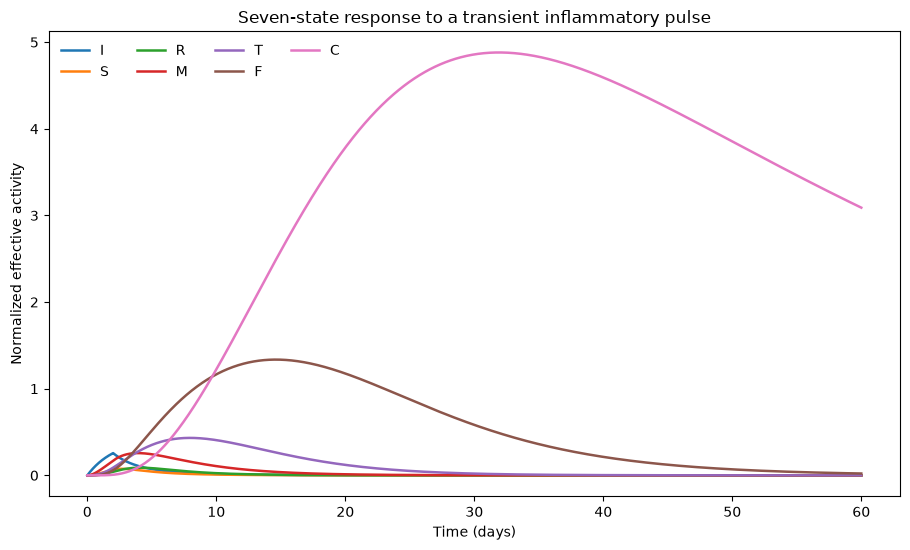

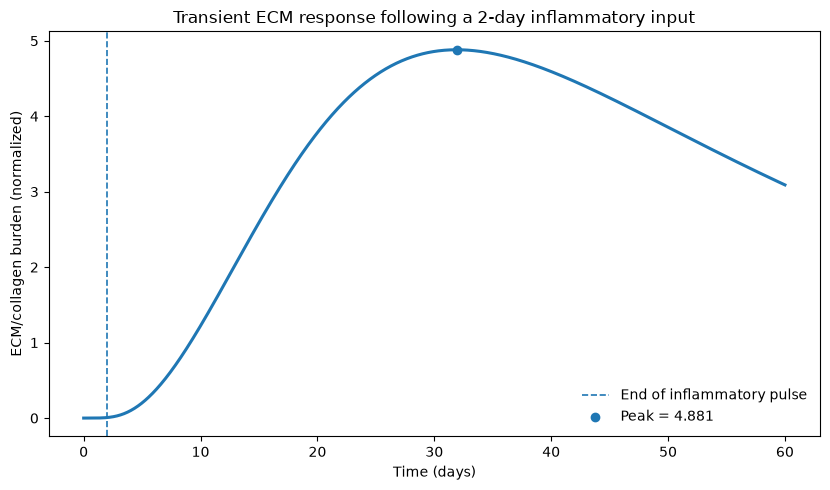

In [10]:
# Figure 1: all seven state trajectories.
fig, ax = plt.subplots(figsize=(9.2, 5.6))
for j, state_name in enumerate(STATE_NAMES):
    ax.plot(baseline_time, baseline_states[j], label=state_name, linewidth=1.8)
ax.set_xlabel("Time (days)")
ax.set_ylabel("Normalized effective activity")
ax.set_title("Seven-state response to a transient inflammatory pulse")
ax.legend(ncol=4, frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "model_A_all_state_trajectories.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "model_A_all_state_trajectories.pdf", bbox_inches="tight")
plt.show()

# Figure 2: ECM response used in the manuscript.
fig, ax = plt.subplots(figsize=(8.4, 5.0))
ax.plot(baseline_time, baseline_states[6], linewidth=2.2)
ax.axvline(2.0, linestyle="--", linewidth=1.2, label="End of inflammatory pulse")
ax.scatter(
    [baseline_metrics["Time_to_peak_days"]],
    [baseline_metrics["Peak_ECM"]],
    zorder=3,
    label=f"Peak = {baseline_metrics['Peak_ECM']:.3f}"
)
ax.set_xlabel("Time (days)")
ax.set_ylabel("ECM/collagen burden (normalized)")
ax.set_title("Transient ECM response following a 2-day inflammatory input")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "model_A_transient_pulse.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "model_A_transient_pulse.pdf", bbox_inches="tight")
plt.show()

In [11]:
def feedback_threshold(p):
    """Model-specific small-signal feedback threshold; not epidemiological R0."""
    route_R = (
        p["beta_R"] * p["alpha_R"] * p["p_S"]
        / (p["delta_I"] * p["delta_R"] * p["delta_S"] * p["K_S"])
    )
    route_M = (
        p["beta_M"] * p["alpha_M"]
        / (p["delta_I"] * p["delta_M"] * p["K_I"])
    )
    return route_R + route_M


def equilibrium_states(I_star, p):
    S_star = (p["p_S"] / p["delta_S"]) * I_star
    R_star = (p["alpha_R"] / p["delta_R"]) * saturation(S_star, p["K_S"])
    M_star = (p["alpha_M"] / p["delta_M"]) * saturation(I_star, p["K_I"])
    T_star = (p["alpha_T"] / p["delta_T"]) * saturation(M_star, p["K_M"])
    F_star = (
        p["alpha_FR"] * saturation(R_star, p["K_FR"])
        + p["alpha_FT"] * saturation(T_star, p["K_FT"])
    ) / p["delta_F"]
    C_star = (p["p_C"] / p["delta_C"]) * F_star
    return dict(zip(STATE_NAMES, [I_star, S_star, R_star, M_star, T_star, F_star, C_star]))


def scalar_equilibrium_function(I, p):
    states = equilibrium_states(float(I), p)
    return (
        p["beta_R"] * states["R"]
        + p["beta_M"] * states["M"]
        - p["delta_I"] * I
    )


def find_equilibrium(p):
    threshold = feedback_threshold(p)
    if threshold <= 1.0:
        return equilibrium_states(0.0, p), threshold, "Disease-free"

    # For threshold > 1, g'(0)>0. Find a strictly positive lower bracket.
    lower = 1e-10
    while scalar_equilibrium_function(lower, p) <= 0.0:
        lower *= 10.0
        if lower >= 1e-2:
            raise RuntimeError("Could not find a positive lower bracket.")

    upper = 1.0
    while scalar_equilibrium_function(upper, p) > 0.0:
        upper *= 2.0
        if upper > 1e12:
            raise RuntimeError("Could not bracket the positive equilibrium.")

    I_star = brentq(
        scalar_equilibrium_function, lower, upper,
        args=(p,), xtol=1e-12, rtol=1e-12
    )
    return equilibrium_states(I_star, p), threshold, "Positive"


baseline_equilibrium, baseline_threshold, baseline_equilibrium_type = find_equilibrium(PARAMETERS)
print(f"Baseline feedback threshold: {baseline_threshold:.6f}")
print("Baseline equilibrium:", baseline_equilibrium_type)
display(pd.DataFrame({
    "State": STATE_NAMES,
    "Equilibrium_value": [baseline_equilibrium[s] for s in STATE_NAMES],
}))
print("Scalar equilibrium residual:",
      f"{scalar_equilibrium_function(baseline_equilibrium['I'], PARAMETERS):.3e}")

assert np.isclose(baseline_threshold, 0.21257142857142855, rtol=1e-6)
assert baseline_equilibrium_type == "Disease-free"

Baseline feedback threshold: 0.212571
Baseline equilibrium: Disease-free


,State,Equilibrium_value
0,I,0.0
1,S,0.0
2,R,0.0
3,M,0.0
4,T,0.0
5,F,0.0
6,C,0.0


Scalar equilibrium residual: 0.000e+00


In [12]:
def model_jacobian(states, p):
    I, S, R, M, T, F, C = [states[k] for k in STATE_NAMES]

    dR_dS = p["alpha_R"] * p["K_S"] / (p["K_S"] + S)**2
    dM_dI = p["alpha_M"] * p["K_I"] / (p["K_I"] + I)**2
    dT_dM = p["alpha_T"] * p["K_M"] / (p["K_M"] + M)**2
    dF_dR = p["alpha_FR"] * p["K_FR"] / (p["K_FR"] + R)**2
    dF_dT = p["alpha_FT"] * p["K_FT"] / (p["K_FT"] + T)**2

    J = np.zeros((7, 7), dtype=float)
    J[0, 0] = -p["delta_I"]
    J[0, 2] = p["beta_R"]
    J[0, 3] = p["beta_M"]

    J[1, 0] = p["p_S"]
    J[1, 1] = -p["delta_S"]

    J[2, 1] = dR_dS
    J[2, 2] = -p["delta_R"]

    J[3, 0] = dM_dI
    J[3, 3] = -p["delta_M"]

    J[4, 3] = dT_dM
    J[4, 4] = -p["delta_T"]

    J[5, 2] = dF_dR
    J[5, 4] = dF_dT
    J[5, 5] = -p["delta_F"]

    J[6, 5] = p["p_C"]
    J[6, 6] = -p["delta_C"]
    return J


def classify_stability(states, p, tolerance=1e-8):
    eigenvalues = np.linalg.eigvals(model_jacobian(states, p))
    maximum_real = float(np.max(np.real(eigenvalues)))
    if maximum_real < -tolerance:
        label = "Locally asymptotically stable"
    elif maximum_real > tolerance:
        label = "Unstable"
    else:
        label = "Non-hyperbolic or borderline"
    return eigenvalues, maximum_real, label


baseline_eigenvalues, baseline_max_real, baseline_stability = classify_stability(
    baseline_equilibrium, PARAMETERS
)
print("Baseline local stability:", baseline_stability)
print("Maximum real eigenvalue:", baseline_max_real)
display(pd.DataFrame({
    "Eigenvalue": baseline_eigenvalues,
    "Real_part": np.real(baseline_eigenvalues),
    "Imaginary_part": np.imag(baseline_eigenvalues),
}))

Baseline local stability: Locally asymptotically stable
Maximum real eigenvalue: -0.025


,Eigenvalue,Real_part,Imaginary_part
0,-0.025000+0.000000j,-0.025000,0.000000
1,-0.120000+0.000000j,-0.120000,0.000000
2,-0.250000+0.000000j,-0.250000,0.000000
3,-0.223642+0.000000j,-0.223642,0.000000
4,-0.516917+0.000000j,-0.516917,0.000000
5,-0.904721+0.126011j,-0.904721,0.126011
6,-0.904721-0.126011j,-0.904721,-0.126011


,Parameter,Baseline,Lower_test,Upper_test,Peak_ECM_lower,Peak_ECM_upper,Peak_ECM_sensitivity,Final_ECM_lower,Final_ECM_upper,Final_ECM_sensitivity,ECM_AUC_lower,ECM_AUC_upper,ECM_AUC_sensitivity,Time_to_peak_days_lower,Time_to_peak_days_upper,Time_to_peak_days_sensitivity
0,beta_R,0.030,0.0270,0.0330,4.862027,4.900347,0.039254,3.073154,3.106943,0.054676,198.037399,199.574179,0.038651,31.85,31.95,0.015674
1,beta_M,0.030,0.0270,0.0330,4.810791,4.953531,0.146216,3.024820,3.158127,0.215711,195.933661,201.759115,0.146513,31.70,32.15,0.070533
2,delta_I,0.500,0.4500,0.5500,5.313754,4.527162,-0.805750,3.449479,2.811732,-1.031969,216.127899,184.614879,-0.792569,32.80,31.25,-0.242947
3,p_S,0.400,0.3600,0.4400,4.822448,4.938741,0.119125,3.051473,3.127973,0.123788,196.297568,201.260755,0.124827,31.90,31.90,0.000000
4,delta_S,1.000,0.9000,1.1000,4.949988,4.824648,-0.128393,3.136921,3.051935,-0.137520,201.681630,196.433600,-0.131991,31.95,31.90,-0.007837
5,alpha_R,0.600,0.5400,0.6600,4.818162,4.943791,0.128689,3.048867,3.131064,0.133006,196.110329,201.480821,0.135071,31.90,31.90,0.000000
6,K_S,0.500,0.4500,0.5500,4.945082,4.827827,-0.120111,3.132170,3.054991,-0.124886,201.531031,196.527375,-0.125845,31.90,31.90,0.000000
7,delta_R,0.700,0.6300,0.7700,4.955821,4.820511,-0.138605,3.141422,3.048859,-0.149780,201.913347,196.269190,-0.141954,31.95,31.90,-0.007837
8,alpha_M,0.500,0.4500,0.5500,4.577530,5.173185,0.610162,2.865824,3.312091,0.722125,186.525307,210.607592,0.605682,31.50,32.30,0.125392
9,K_I,0.500,0.4500,0.5500,5.149865,4.648874,-0.513193,3.299120,2.914676,-0.622086,209.658006,189.418914,-0.509024,32.35,31.55,-0.125392


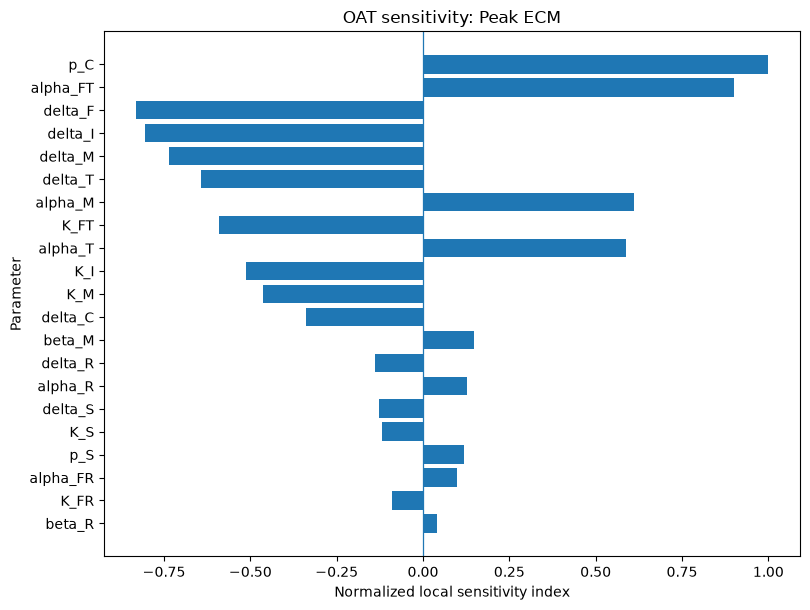

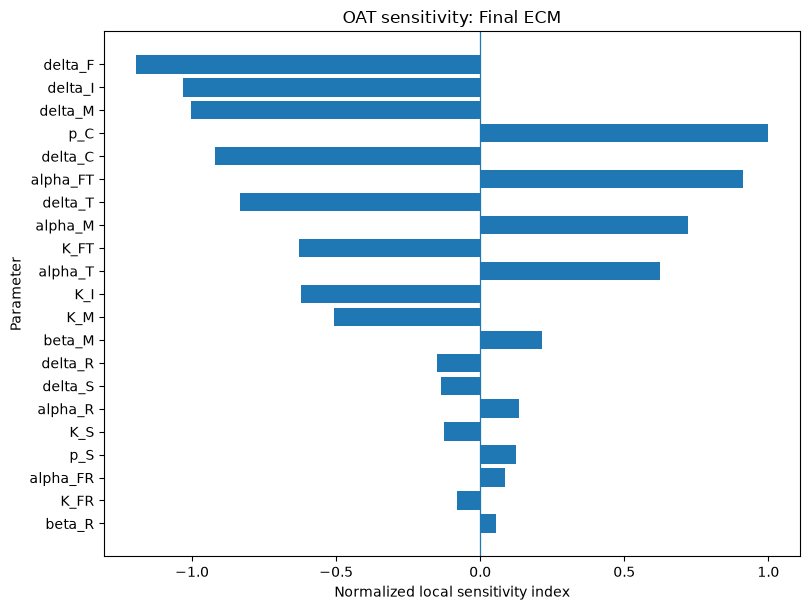

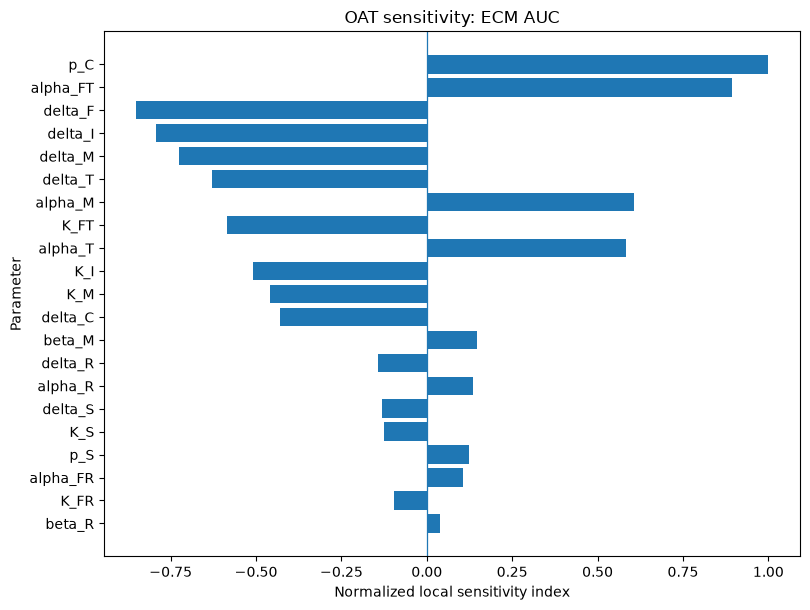

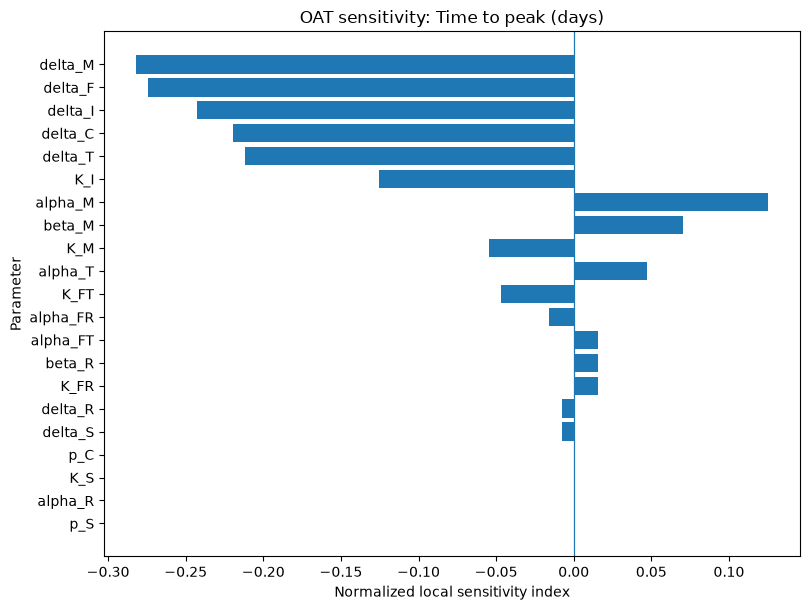

In [13]:
OAT_FRACTION = 0.10

oat_records = []
for parameter_name in PARAMETER_NAMES:
    baseline_value = PARAMETERS[parameter_name]
    lower_bound, upper_bound = PARAMETER_BOUNDS[parameter_name]

    lower_value = max(lower_bound, baseline_value * (1.0 - OAT_FRACTION))
    upper_value = min(upper_bound, baseline_value * (1.0 + OAT_FRACTION))
    if upper_value <= lower_value:
        raise ValueError(f"Invalid OAT perturbation interval for {parameter_name}.")

    p_lower = PARAMETERS.copy()
    p_upper = PARAMETERS.copy()
    p_lower[parameter_name] = lower_value
    p_upper[parameter_name] = upper_value

    t_lower, y_lower = integrate_pulse(p_lower)
    t_upper, y_upper = integrate_pulse(p_upper)
    metrics_lower = calculate_ecm_metrics(t_lower, y_lower)
    metrics_upper = calculate_ecm_metrics(t_upper, y_upper)

    record = {
        "Parameter": parameter_name,
        "Baseline": baseline_value,
        "Lower_test": lower_value,
        "Upper_test": upper_value,
    }

    for metric_name in [
        "Peak_ECM", "Final_ECM", "ECM_AUC", "Time_to_peak_days"
    ]:
        y0 = baseline_metrics[metric_name]
        sensitivity = (
            (metrics_upper[metric_name] - metrics_lower[metric_name])
            / (upper_value - lower_value)
            * baseline_value / y0
        )
        record[f"{metric_name}_lower"] = metrics_lower[metric_name]
        record[f"{metric_name}_upper"] = metrics_upper[metric_name]
        record[f"{metric_name}_sensitivity"] = sensitivity

    oat_records.append(record)

oat_results = pd.DataFrame(oat_records)
oat_results.to_csv(RESULTS_DIR / "model_A_oat_sensitivity_results.csv", index=False)
display(oat_results)

# Ranked sensitivity plots: absolute magnitude determines ordering; signed values are shown.
sensitivity_specs = [
    ("Peak_ECM", "Peak ECM"),
    ("Final_ECM", "Final ECM"),
    ("ECM_AUC", "ECM AUC"),
    ("Time_to_peak_days", "Time to peak (days)"),
]

for metric_key, metric_label in sensitivity_specs:
    col = f"{metric_key}_sensitivity"
    ranked = oat_results[["Parameter", col]].copy()
    ranked["Absolute"] = ranked[col].abs()
    ranked = ranked.sort_values("Absolute", ascending=True)

    fig, ax = plt.subplots(figsize=(8.2, 6.2))
    ax.barh(ranked["Parameter"], ranked[col])
    ax.axvline(0.0, linewidth=0.9)
    ax.set_xlabel("Normalized local sensitivity index")
    ax.set_ylabel("Parameter")
    ax.set_title(f"OAT sensitivity: {metric_label}")
    fig.tight_layout()
    filename = f"sensitivity_{metric_key.lower()}.png"
    fig.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / filename.replace(".png", ".pdf"), bbox_inches="tight")
    plt.show()

# Save a concise baseline metric table used in the manuscript.
pd.DataFrame(
    [{"Metric": k, "Baseline_value": v} for k, v in baseline_metrics.items()]
).to_csv(RESULTS_DIR / "model_A_sensitivity_baseline_metrics.csv", index=False)

In [14]:
# Generate a reproducible 200 x 21 LHS design using the manuscript's uniform bounds.
lower_bounds = np.array([PARAMETER_BOUNDS[k][0] for k in PARAMETER_NAMES], dtype=float)
upper_bounds = np.array([PARAMETER_BOUNDS[k][1] for k in PARAMETER_NAMES], dtype=float)

sampler = qmc.LatinHypercube(d=len(PARAMETER_NAMES), seed=RANDOM_SEED)
unit_design = sampler.random(n=N_LHS)
sample_values = qmc.scale(unit_design, lower_bounds, upper_bounds)

lhs_samples = pd.DataFrame(sample_values, columns=PARAMETER_NAMES)
lhs_samples.insert(0, "Sample_ID", np.arange(1, N_LHS + 1))

assert lhs_samples.shape == (N_LHS, len(PARAMETER_NAMES) + 1)
assert np.isfinite(lhs_samples[PARAMETER_NAMES].to_numpy()).all()

for name, (lo, hi) in PARAMETER_BOUNDS.items():
    assert lhs_samples[name].between(lo, hi).all(), f"Out-of-range LHS value: {name}"

lhs_samples.to_csv(RESULTS_DIR / "model_A_lhs_parameter_samples.csv", index=False)
display(lhs_samples.head())
print(f"LHS design: {N_LHS} samples x {len(PARAMETER_NAMES)} parameters")

,Sample_ID,beta_R,beta_M,delta_I,p_S,delta_S,alpha_R,K_S,delta_R,alpha_M,...,alpha_T,K_M,delta_T,alpha_FR,K_FR,alpha_FT,K_FT,delta_F,p_C,delta_C
0,1,0.072374,0.043858,0.405449,0.603295,1.194983,1.136942,3.826887,1.465823,0.353268,...,0.817107,1.246928,0.310344,0.790837,0.770128,0.171677,1.638822,0.286749,0.185259,0.024825
1,2,0.162560,0.121928,0.508714,0.215586,1.707142,0.320878,2.269003,0.394281,0.332129,...,0.624424,1.277430,0.290018,0.500985,1.499662,0.718439,1.529593,0.194670,0.247926,0.006087
2,3,0.099929,0.180934,0.622261,0.539974,0.880344,0.431954,0.316670,0.822364,0.668276,...,0.817287,1.523803,0.162136,0.258539,0.787123,0.632174,1.264079,0.143981,0.531337,0.067270
3,4,0.079139,0.028744,0.299904,0.445456,1.308871,0.776202,2.132214,1.445264,0.405733,...,0.584851,1.780688,0.557640,0.344450,1.530505,0.588367,0.768421,0.159636,0.466886,0.055684
4,5,0.017935,0.168266,0.495544,0.394957,0.723271,0.944350,0.667229,1.126458,0.420616,...,0.449571,0.412219,0.317818,0.770329,0.583688,0.160557,0.617486,0.188514,0.543975,0.044709


LHS design: 200 samples x 21 parameters


In [15]:
simulation_records = []
failure_records = []

for sample_number, row in lhs_samples.iterrows():
    sample_id = int(row["Sample_ID"])
    p_sample = {name: float(row[name]) for name in PARAMETER_NAMES}

    try:
        t_sample, y_sample = integrate_pulse(p_sample)
        metrics = calculate_ecm_metrics(t_sample, y_sample)
        simulation_records.append({
            "Sample_ID": sample_id,
            **p_sample,
            **metrics,
        })
    except Exception as exc:
        failure_records.append({"Sample_ID": sample_id, "Error": repr(exc)})

    if sample_id % 25 == 0:
        print(f"Completed {sample_id}/{N_LHS} parameter sets.")

lhs_results = pd.DataFrame(simulation_records)
lhs_failures = pd.DataFrame(failure_records, columns=["Sample_ID", "Error"])

if len(lhs_results) != N_LHS or not lhs_failures.empty:
    display(lhs_failures)
    raise RuntimeError("LHS simulations incomplete. Do not interpret partial results.")

outcome_columns = ["Peak_ECM", "Final_ECM", "ECM_AUC", "Time_to_peak_days"]
if not np.isfinite(lhs_results[outcome_columns].to_numpy()).all():
    raise ValueError("Non-finite LHS outcome values detected.")

lhs_results.to_csv(RESULTS_DIR / "model_A_lhs_simulation_results.csv", index=False)
lhs_failures.to_csv(RESULTS_DIR / "model_A_lhs_simulation_failures.csv", index=False)

summary_records = []
for outcome in outcome_columns:
    values = lhs_results[outcome].to_numpy(dtype=float)
    summary_records.append({
        "Outcome": outcome,
        "Minimum": np.min(values),
        "5th_percentile": np.percentile(values, 5),
        "25th_percentile": np.percentile(values, 25),
        "Median": np.median(values),
        "75th_percentile": np.percentile(values, 75),
        "95th_percentile": np.percentile(values, 95),
        "Maximum": np.max(values),
        "Baseline": baseline_metrics[outcome],
    })

uncertainty_summary = pd.DataFrame(summary_records)
display(uncertainty_summary)
uncertainty_summary.to_csv(RESULTS_DIR / "model_A_uncertainty_summary.csv", index=False)

print("Successful LHS simulations:", len(lhs_results))
print("Failed LHS simulations:", len(lhs_failures))

Completed 25/200 parameter sets.
Completed 50/200 parameter sets.
Completed 75/200 parameter sets.
Completed 100/200 parameter sets.
Completed 125/200 parameter sets.
Completed 150/200 parameter sets.
Completed 175/200 parameter sets.
Completed 200/200 parameter sets.


,Outcome,Minimum,5th_percentile,25th_percentile,Median,75th_percentile,95th_percentile,Maximum,Baseline
0,Peak_ECM,0.019471,0.120877,0.511368,1.751416,5.985456,23.677121,81.461143,4.881117
1,Final_ECM,0.005954,0.026021,0.218016,0.904922,4.477635,23.677121,80.820069,3.089956
2,ECM_AUC,0.712270,4.157806,19.211788,63.950332,214.243271,618.123659,2882.962113,198.802950
3,Time_to_peak_days,15.200000,17.847500,23.325000,30.325000,47.775000,60.000000,60.000000,31.900000


Successful LHS simulations: 200
Failed LHS simulations: 0


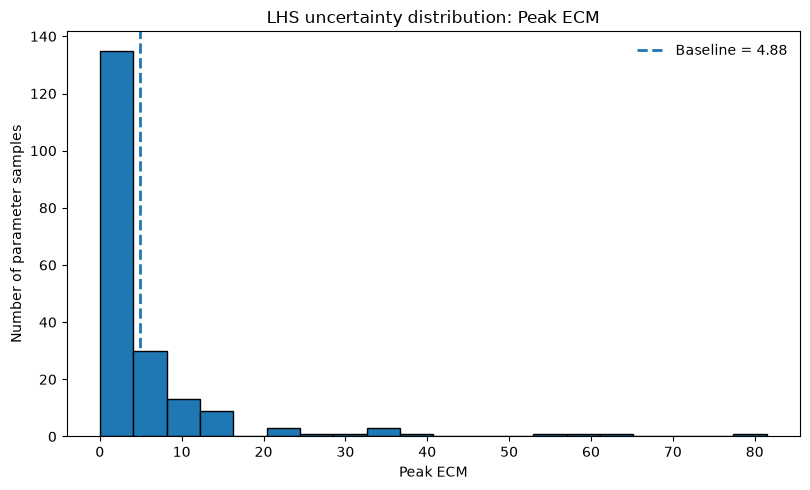

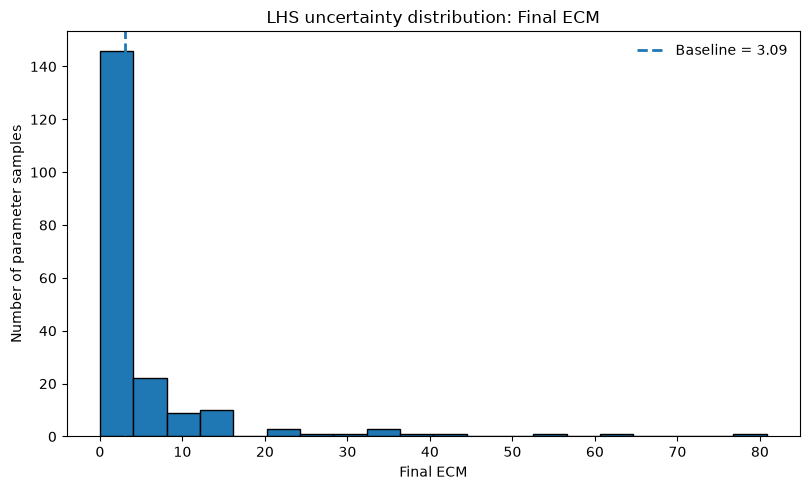

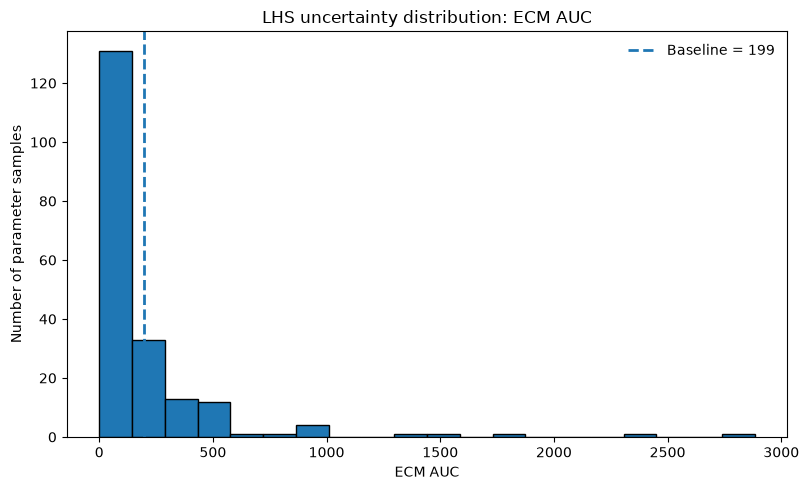

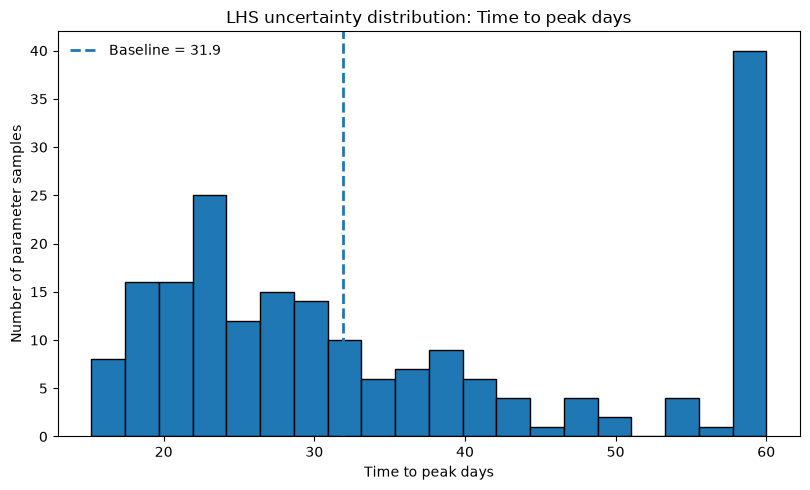

,Outcome,Baseline,LHS_median,LHS_5th_percentile,LHS_95th_percentile,Baseline_within_5th_95th_percentiles
0,Peak_ECM,4.881117,1.751416,0.120877,23.677121,True
1,Final_ECM,3.089956,0.904922,0.026021,23.677121,True
2,ECM_AUC,198.802950,63.950332,4.157806,618.123659,True
3,Time_to_peak_days,31.900000,30.325000,17.847500,60.000000,True


In [16]:
for outcome in outcome_columns:
    values = lhs_results[outcome].to_numpy(dtype=float)
    baseline_value = baseline_metrics[outcome]

    fig, ax = plt.subplots(figsize=(8.2, 5.0))
    ax.hist(values, bins=20, edgecolor="black")
    ax.axvline(
        baseline_value,
        linestyle="--",
        linewidth=2,
        label=f"Baseline = {baseline_value:.3g}"
    )
    ax.set_xlabel(outcome.replace("_", " "))
    ax.set_ylabel("Number of parameter samples")
    ax.set_title(f"LHS uncertainty distribution: {outcome.replace('_', ' ')}")
    ax.legend(frameon=False)
    fig.tight_layout()

    filename = f"uncertainty_{outcome.lower()}.png"
    fig.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / filename.replace(".png", ".pdf"), bbox_inches="tight")
    plt.show()

# Baseline-vs-LHS percentile comparison.
comparison_records = []
for outcome in outcome_columns:
    vals = lhs_results[outcome].to_numpy(dtype=float)
    lo, hi = np.percentile(vals, [5, 95])
    comparison_records.append({
        "Outcome": outcome,
        "Baseline": baseline_metrics[outcome],
        "LHS_median": np.median(vals),
        "LHS_5th_percentile": lo,
        "LHS_95th_percentile": hi,
        "Baseline_within_5th_95th_percentiles": bool(lo <= baseline_metrics[outcome] <= hi),
    })
baseline_lhs_comparison = pd.DataFrame(comparison_records)
display(baseline_lhs_comparison)
baseline_lhs_comparison.to_csv(
    RESULTS_DIR / "model_A_baseline_uncertainty_comparison.csv", index=False
)

In [17]:
# Spearman correlations are exploratory associations across the sampled design.
# They are not causal effects and do not replace the local OAT analysis.
spearman_records = []
for parameter_name in PARAMETER_NAMES:
    for outcome in outcome_columns:
        rho, p_value = spearmanr(
            lhs_results[parameter_name].to_numpy(dtype=float),
            lhs_results[outcome].to_numpy(dtype=float)
        )
        spearman_records.append({
            "Parameter": parameter_name,
            "Outcome": outcome,
            "Spearman_rho": float(rho),
            "p_value": float(p_value),
        })

spearman_results = pd.DataFrame(spearman_records)
spearman_results.to_csv(
    RESULTS_DIR / "model_A_spearman_parameter_outcome.csv", index=False
)
display(spearman_results.sort_values(
    ["Outcome", "Spearman_rho"],
    ascending=[True, False]
).groupby("Outcome").head(8))

,Parameter,Outcome,Spearman_rho,p_value
78,p_C,ECM_AUC,0.407151,2.188734e-09
46,alpha_T,ECM_AUC,0.268928,1.178484e-04
6,beta_M,ECM_AUC,0.224182,1.416543e-03
58,alpha_FR,ECM_AUC,0.222120,1.571536e-03
34,alpha_M,ECM_AUC,0.151871,3.180997e-02
66,alpha_FT,ECM_AUC,0.118270,9.532124e-02
14,p_S,ECM_AUC,0.097267,1.706272e-01
22,alpha_R,ECM_AUC,0.055551,4.346334e-01
77,p_C,Final_ECM,0.337777,1.000820e-06
5,beta_M,Final_ECM,0.227713,1.183297e-03


In [18]:
equilibrium_records = []
stability_records = []

for _, row in lhs_samples.iterrows():
    sample_id = int(row["Sample_ID"])
    p_sample = {name: float(row[name]) for name in PARAMETER_NAMES}

    eq_states, threshold, eq_type = find_equilibrium(p_sample)
    eigenvalues, max_real, stability = classify_stability(eq_states, p_sample)

    equilibrium_records.append({
        "Sample_ID": sample_id,
        "Feedback_Threshold": threshold,
        "Equilibrium_Type": eq_type,
        **{f"{state}_equilibrium": eq_states[state] for state in STATE_NAMES},
    })
    stability_records.append({
        "Sample_ID": sample_id,
        "Equilibrium_Type": eq_type,
        "Feedback_Threshold": threshold,
        "Maximum_Real_Eigenvalue": max_real,
        "Local_Stability": stability,
    })

equilibrium_results = pd.DataFrame(equilibrium_records)
stability_results = pd.DataFrame(stability_records)

equilibrium_results.to_csv(RESULTS_DIR / "lhs_equilibrium_results.csv", index=False)
stability_results.to_csv(RESULTS_DIR / "lhs_equilibrium_stability_results.csv", index=False)

print("Equilibrium classification:")
display(equilibrium_results["Equilibrium_Type"].value_counts().rename("Number of samples"))
print("Local stability classification:")
display(stability_results["Local_Stability"].value_counts().rename("Number of equilibria"))

classification_table = pd.crosstab(
    stability_results["Equilibrium_Type"],
    stability_results["Local_Stability"]
)
display(classification_table)

# Consistency check: no positive equilibrium should be classified as unstable
# for this model under the stated analytical structure and sampled positive parameters.
positive_rows = stability_results[stability_results["Equilibrium_Type"] == "Positive"]
if not positive_rows.empty and (positive_rows["Local_Stability"] == "Unstable").any():
    warnings.warn(
        "At least one positive equilibrium was numerically classified as unstable. "
        "Inspect the Jacobian, root residual, and solver precision before reporting."
    )

Equilibrium classification:


Equilibrium_Type
Disease-free    167
Positive         33
Name: Number of samples, dtype: int64

Local stability classification:


Local_Stability
Locally asymptotically stable    200
Name: Number of equilibria, dtype: int64

Local_Stability,Locally asymptotically stable
Equilibrium_Type,
Disease-free,167
Positive,33


,Sample_ID,Feedback_Threshold,Equilibrium_Type,Simulated_ECM_at_540_days,Calculated_ECM_equilibrium,Relative_difference,Relative_difference_percent,Peak_at_final_time
0,144,4.932891,Positive,12.149644,12.151951,0.00019,0.018985,True


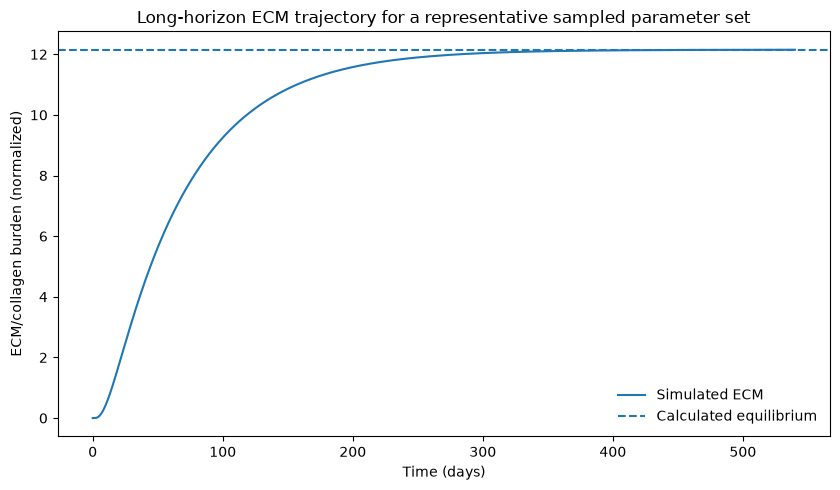

In [19]:
# Select the positive equilibrium closest to the median positive-equilibrium ECM value.
positive_eq = equilibrium_results[equilibrium_results["Equilibrium_Type"] == "Positive"].copy()

if positive_eq.empty:
    print("No positive equilibrium occurred in this LHS ensemble; long-horizon positive-branch diagnostic skipped.")
else:
    target_ecm = positive_eq["C_equilibrium"].median()
    selected_row = positive_eq.iloc[
        (positive_eq["C_equilibrium"] - target_ecm).abs().argmin()
    ]
    selected_id = int(selected_row["Sample_ID"])
    selected_parameter_row = lhs_samples.loc[
        lhs_samples["Sample_ID"] == selected_id
    ].iloc[0]
    selected_parameters = {
        name: float(selected_parameter_row[name]) for name in PARAMETER_NAMES
    }
    selected_eq, selected_threshold, selected_type = find_equilibrium(selected_parameters)

    # Use a longer horizon to assess approach to the calculated equilibrium.
    long_time, long_states = integrate_pulse(
        selected_parameters,
        end_day=540.0,
        pulse_amplitude=0.2,
        pulse_duration=2.0,
        rtol=1e-8,
        atol=1e-10,
        max_step=0.05,
    )
    long_ecm = long_states[6]
    final_simulated_ecm = float(long_ecm[-1])
    equilibrium_ecm = float(selected_eq["C"])
    relative_difference = (
        abs(final_simulated_ecm - equilibrium_ecm) / abs(equilibrium_ecm)
        if abs(equilibrium_ecm) > 1e-12 else np.nan
    )

    long_trajectory = pd.DataFrame(long_states.T, columns=STATE_NAMES)
    long_trajectory.insert(0, "Time_days", long_time)
    long_trajectory.to_csv(
        RESULTS_DIR / "selected_sample_long_term_trajectory.csv", index=False
    )

    convergence = pd.DataFrame([{
        "Sample_ID": selected_id,
        "Feedback_Threshold": selected_threshold,
        "Equilibrium_Type": selected_type,
        "Simulated_ECM_at_540_days": final_simulated_ecm,
        "Calculated_ECM_equilibrium": equilibrium_ecm,
        "Relative_difference": relative_difference,
        "Relative_difference_percent": 100 * relative_difference,
        "Peak_at_final_time": bool(np.argmax(long_ecm) == len(long_ecm) - 1),
    }])
    display(convergence)
    convergence.to_csv(
        RESULTS_DIR / "long_term_equilibrium_convergence.csv", index=False
    )

    fig, ax = plt.subplots(figsize=(8.5, 5.0))
    ax.plot(long_time, long_ecm, label="Simulated ECM")
    ax.axhline(
        equilibrium_ecm,
        linestyle="--",
        label="Calculated equilibrium"
    )
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("ECM/collagen burden (normalized)")
    ax.set_title("Long-horizon ECM trajectory for a representative sampled parameter set")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "long_term_equilibrium_diagnostic.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / "long_term_equilibrium_diagnostic.pdf", bbox_inches="tight")
    plt.show()

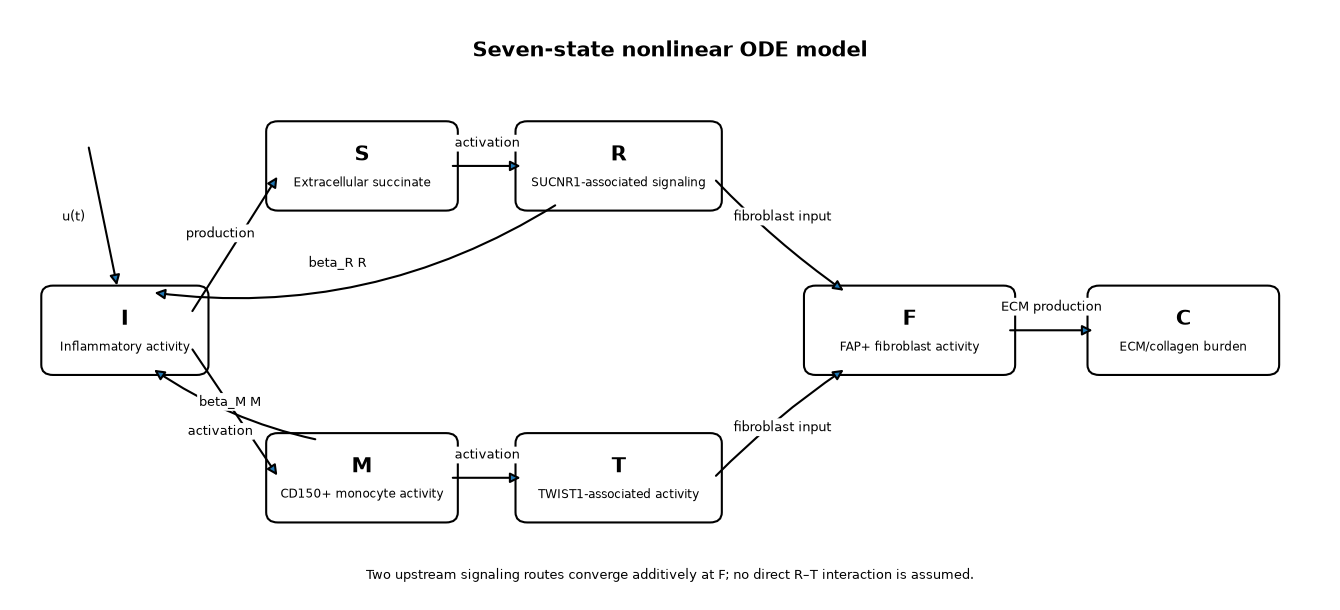

In [20]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13.5, 6.2))
ax.set_xlim(0, 13.5)
ax.set_ylim(0, 7)
ax.axis("off")

nodes = {
    "I": (0.4, 2.75, 1.55, 0.9, "I", "Inflammatory activity"),
    "S": (2.7, 4.7, 1.8, 0.9, "S", "Extracellular succinate"),
    "R": (5.25, 4.7, 1.95, 0.9, "R", "SUCNR1-associated signaling"),
    "M": (2.7, 1.0, 1.8, 0.9, "M", "CD150+ monocyte activity"),
    "T": (5.25, 1.0, 1.95, 0.9, "T", "TWIST1-associated activity"),
    "F": (8.2, 2.75, 2.0, 0.9, "F", "FAP+ fibroblast activity"),
    "C": (11.1, 2.75, 1.8, 0.9, "C", "ECM/collagen burden"),
}

for key, (x, y, w, h, symbol, label) in nodes.items():
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08,rounding_size=0.12",
        linewidth=1.5,
        facecolor="white",
    )
    ax.add_patch(patch)
    ax.text(x + w/2, y + 0.58, symbol, ha="center", va="center",
            fontsize=15, fontweight="bold")
    ax.text(x + w/2, y + 0.25, label, ha="center", va="center", fontsize=8.5)

def arrow(start, end, rad=0.0, label=None, label_xy=None):
    ax.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>", mutation_scale=15,
        linewidth=1.5, connectionstyle=f"arc3,rad={rad}"
    ))
    if label and label_xy:
        ax.text(*label_xy, label, ha="center", va="center", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))

arrow((1.85, 3.4), (2.75, 5.05), label="production", label_xy=(2.15, 4.35))
arrow((4.5, 5.15), (5.25, 5.15), label="activation", label_xy=(4.88, 5.42))
arrow((1.85, 3.0), (2.75, 1.45), label="activation", label_xy=(2.15, 2.0))
arrow((4.5, 1.45), (5.25, 1.45), label="activation", label_xy=(4.88, 1.72))
arrow((7.2, 5.0), (8.55, 3.65), rad=0.05, label="fibroblast input", label_xy=(7.9, 4.55))
arrow((7.2, 1.45), (8.55, 2.75), rad=-0.05, label="fibroblast input", label_xy=(7.9, 2.05))
arrow((10.2, 3.2), (11.1, 3.2), label="ECM production", label_xy=(10.65, 3.48))

# External input to inflammation.
arrow((0.8, 5.4), (1.1, 3.7), label="u(t)", label_xy=(0.65, 4.55))
# Feedback arrows into inflammation.
arrow((5.6, 4.7), (1.45, 3.65), rad=-0.18, label="beta_R R", label_xy=(3.35, 4.0))
arrow((3.15, 1.9), (1.45, 2.75), rad=-0.10, label="beta_M M", label_xy=(2.25, 2.35))

ax.text(6.75, 6.45, "Seven-state nonlinear ODE model", ha="center",
        fontsize=15, fontweight="bold")
ax.text(6.75, 0.25,
        "Two upstream signaling routes converge additively at F; no direct R–T interaction is assumed.",
        ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "seven_state_model_structure.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "seven_state_model_structure.pdf", bbox_inches="tight")
plt.show()

In [22]:

# Rebuild baseline reproduction checks
# This cell is required by the final validation section.

EXPECTED_BASELINE = {
    "Peak_ECM": 4.881117232924121,
    "Final_ECM": 3.0899555369174707,
    "Time_to_peak_days": 31.9,
}

checks = []

for metric, expected in EXPECTED_BASELINE.items():
    actual = baseline_metrics[metric]

    checks.append({
        "Metric": metric,
        "Expected_from_manuscript": expected,
        "Recomputed": actual,
        "Absolute_difference": abs(actual - expected),
        "Passed": np.isclose(
            actual,
            expected,
            rtol=2e-4,
            atol=1e-6
        ),
    })

baseline_check_table = pd.DataFrame(checks)

display(baseline_check_table)

# Stop if any baseline result does not match.
if not baseline_check_table["Passed"].all():
    raise RuntimeError(
        "Baseline reproduction check failed. "
        "Check model parameters and numerical integration."
    )

print("Baseline numerical reproduction check passed.")


,Metric,Expected_from_manuscript,Recomputed,Absolute_difference,Passed
0,Peak_ECM,4.881117,4.881117,0.000000e+00,True
1,Final_ECM,3.089956,3.089956,0.000000e+00,True
2,Time_to_peak_days,31.900000,31.900000,3.552714e-15,True


Baseline numerical reproduction check passed.


In [23]:
# Core numerical checks.
assert len(PARAMETER_NAMES) == 21
assert len(lhs_samples) == N_LHS
assert len(lhs_results) == N_LHS
assert lhs_failures.empty
assert baseline_check_table["Passed"].all()
assert np.isfinite(baseline_states).all()
assert np.min(baseline_states) >= -1e-8
assert np.isfinite(oat_results.filter(like="_sensitivity").to_numpy()).all()
assert np.isfinite(lhs_results[outcome_columns].to_numpy()).all()

# Export a compact run manifest documenting the computational design.
manifest = {
    "model": "Seven-state nonlinear ODE model of succinate-immune-stromal signaling",
    "state_order": STATE_NAMES,
    "parameter_order": PARAMETER_NAMES,
    "baseline_parameters": PARAMETERS,
    "parameter_bounds": {k: list(v) for k, v in PARAMETER_BOUNDS.items()},
    "pulse_amplitude": 0.2,
    "pulse_duration_days": 2.0,
    "baseline_horizon_days": 60.0,
    "lhs_sample_size": N_LHS,
    "lhs_sampling": "SciPy LatinHypercube with uniform scaling to stated bounds",
    "random_seed": RANDOM_SEED,
    "solver": "DOP853",
    "rtol": 1e-8,
    "atol": 1e-10,
    "max_step_days": 0.05,
    "interpretation_note": (
        "Normalized effective states; exploratory parameters; LHS quantiles are "
        "conditional simulation summaries, not clinical confidence intervals."
    ),
}
with open(RESULTS_DIR / "run_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

# List generated figures and data files.
figure_files = sorted([p.name for p in FIGURE_DIR.glob("*") if p.is_file()])
result_files = sorted([p.name for p in RESULTS_DIR.glob("*") if p.is_file()])

print("FINAL CHECKS PASSED")
print("Figures saved:", len(figure_files))
for name in figure_files:
    print(" -", name)
print("\nResult files saved:", len(result_files))
for name in result_files:
    print(" -", name)

print("\nManuscript-specific figure filenames:")
for required in [
    "seven_state_model_structure.png",
    "model_A_transient_pulse.png",
    "sensitivity_peak_ecm.png",
    "sensitivity_final_ecm.png",
    "sensitivity_ecm_auc.png",
    "sensitivity_time_to_peak_days.png",
    "uncertainty_peak_ecm.png",
    "uncertainty_final_ecm.png",
    "uncertainty_ecm_auc.png",
    "uncertainty_time_to_peak_days.png",
]:
    status = "FOUND" if (FIGURE_DIR / required).exists() else "MISSING"
    print(f"{status}: {required}")

FINAL CHECKS PASSED
Figures saved: 25
 - long_term_equilibrium_diagnostic.pdf
 - long_term_equilibrium_diagnostic.png
 - model_A_all_state_trajectories.pdf
 - model_A_all_state_trajectories.png
 - model_A_transient_pulse.pdf
 - model_A_transient_pulse.png
 - sensitivity_ecm_auc.pdf
 - sensitivity_ecm_auc.png
 - sensitivity_final_ecm.pdf
 - sensitivity_final_ecm.png
 - sensitivity_peak_ecm.pdf
 - sensitivity_peak_ecm.png
 - sensitivity_time_to_peak_days.pdf
 - sensitivity_time_to_peak_days.png
 - seven_state_model_structure.pdf
 - seven_state_model_structure.png
 - seven_state_model_structure.svg
 - uncertainty_ecm_auc.pdf
 - uncertainty_ecm_auc.png
 - uncertainty_final_ecm.pdf
 - uncertainty_final_ecm.png
 - uncertainty_peak_ecm.pdf
 - uncertainty_peak_ecm.png
 - uncertainty_time_to_peak_days.pdf
 - uncertainty_time_to_peak_days.png

Result files saved: 64
 - baseline_equilibrium_values.csv
 - core_parameter_evidence_audit.csv
 - experimental_evidence_inventory.csv
 - extended_simulati